In [ ]:
val = 0.7026546

print(round(val, 3))

0.703


In [3]:
import yt
import unyt
from unyt import unyt_quantity, unyt_array, km, s, Mpc, kg, m, Msun, kpc
from unyt import Gyr, Mpc, km, s
from unyt.physical_constants import G as G_unyt, kboltz, mp as mp_unyt  # G, k_B, m_p

import numpy as np
import matplotlib.pyplot as plt
import caesar
import pynbody as pnb
import pynbody.units as u
import pynbody.array as pna

import dill
import os
from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units, G
#from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units,

code = 'Simba'

snap_file = '/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_3224/snap_halo_3224_151.hdf5'

# ADD CAESAR FILEPATH HERE TOO

snap = yt.load(snap_file)#, unit_system='cgs')
s = pnb.load(snap_file)

id_filepath = "/home/b/babul/stlock/entropy_profiles/finished/ids_formatted.txt" # containing halo data/ids

## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                  'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                  'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                      'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
           'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')

yt : [INFO     ] 2025-06-09 04:28:31,073 ComovingIntegrationOn does not exist, falling back to OmegaLambda
yt : [INFO     ] 2025-06-09 04:28:31,084 Calculating time from 1.000e+00 to be 4.375e+17 seconds
yt : [INFO     ] 2025-06-09 04:28:31,085 Assuming length units are in kpc/h (comoving)
yt : [INFO     ] 2025-06-09 04:28:31,157 Parameters: current_time              = 4.3748565942961094e+17 s
yt : [INFO     ] 2025-06-09 04:28:31,158 Parameters: domain_dimensions         = [1 1 1]
yt : [INFO     ] 2025-06-09 04:28:31,158 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2025-06-09 04:28:31,159 Parameters: domain_right_edge         = [200000. 200000. 200000.]
yt : [INFO     ] 2025-06-09 04:28:31,159 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2025-06-09 04:28:31,160 Parameters: current_redshift          = 4.440892098500626e-16
yt : [INFO     ] 2025-06-09 04:28:31,160 Parameters: omega_lambda              = 0.7
yt : [INFO     ] 2025-06-09 04:28:31,160 

In [2]:
# Get data, and some functions

data = snap.all_data()

def gas_entropy(field, data):
    return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)

def gas_entropy2(field, data):
    return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)

snap.add_field(
    ("gas", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy,
    sampling_type="cell",
)

snap.add_field(
    ("PartType0", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy2,
    sampling_type="particle",
    force_override=True
)

gas_entropy = data['gas', 'entropy']

yt : [INFO     ] 2025-05-27 14:49:17,986 Allocating for 4.322e+07 particles


Loading particle index: 100%|██████████| 76/76 [00:00<00:00, 3872.90it/s]
/gpfs/fs1/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: invalid value encountered in power
  out_arr = func(
/gpfs/fs1/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: divide by zero encountered in power
  out_arr = func(


In [1]:
import numpy as np

# Path to your text file
halo_info_file = "/home/b/babul/stlock/entropy_profiles/finished_script_and_plots/Matched_Elite_halos-at-z0-Level1.txt"

# Skip the first line since it's a comment/header
halo_data = np.loadtxt(halo_info_file)

# Check shape: should be (40, 11) if you have 40 halos and 11 columns
print(halo_data.shape)


(40, 11)


In [3]:
for row in halo_data:
    halo_id = int(row[0])               # Origin halo ID (your folder name's number)
    caesar_group_id = int(row[1])       # Caesar group ID
    central_galaxy_id = int(row[2])     # Caesar central galaxy ID
    total_mass = row[3]                  # Total mass of the group
    contam_mass = row[4]                 # Contamination mass

    # Optional: Access position columns (5,6,7), distances, etc.
    pos_x, pos_y, pos_z = row[5:8]
    dist_to_ic_center = row[8]

    print(f"halo_{halo_id}, x,y,z = {pos_x}, {pos_y}, {pos_z}")
    
    # Now you can build the path to the folder and file
    halo_folder = f"halo_{halo_id}"
    snapshot_file = f"{halo_folder}/snap_halo_{halo_id}_151.hdf5"
    caesar_file = f"{halo_folder}/Groups/Caesar_halo_{halo_id}_151.hdf5"

    #print(f"Processing {halo_folder}")
    #print(f"Snapshot: {snapshot_file}")
    #print(f"Caesar: {caesar_file}")
    
    # Call your entropy plotting function here!
    # plot_entropy(snapshot_file, caesar_file, other_params)


halo_6312, x,y,z = 105112.0625, 101180.3125, 108493.390625
halo_8126, x,y,z = 93242.125, 105892.5078125, 95219.984375
halo_9674, x,y,z = 104467.59375, 101053.2265625, 100381.140625
halo_4804, x,y,z = 105444.75, 103770.0625, 95827.328125
halo_6822, x,y,z = 92582.5, 101291.421875, 98105.390625
halo_7688, x,y,z = 102369.9921875, 99910.390625, 99584.0
halo_9654, x,y,z = 99856.3125, 97593.21875, 102823.875
halo_8189, x,y,z = 99976.109375, 107457.8203125, 106091.828125
halo_4434, x,y,z = 100739.6171875, 103107.71875, 98851.296875
halo_3814, x,y,z = 108000.15625, 96456.265625, 103533.828125
halo_3735, x,y,z = 104586.0234375, 99667.171875, 104885.4609375
halo_3410, x,y,z = 94810.1875, 99660.78125, 100139.796875
halo_2007, x,y,z = 107380.6875, 100932.34375, 105781.6875
halo_3224, x,y,z = 103115.6640625, 96391.046875, 97840.25
halo_2919, x,y,z = 99709.0703125, 100018.4765625, 92499.5078125
halo_4581, x,y,z = 99065.546875, 100606.34375, 97847.5703125
halo_1283, x,y,z = 98879.984375, 99538.6640625

# Caesar Halo Finding

In [ ]:
import os
from pathlib import Path
import caesar
import yt
import numpy as np
import matplotlib.pyplot as plt

# Directory containing all the halo subdirectories
base_dir = '/home/b/babul/wcui/runs/HYENAS'

# Loop over each subdirectory that starts with "halo_"
for halo_dir in sorted(Path(base_dir).glob('halo_*')):
    # Extract halo number for labeling
    halo_number = halo_dir.name.split('_')[1]
    print(halo_number)

    obj = caesar.load(f'/home/b/babul/wcui/runs/HYENAS/halo_{halo_number}/Groups/Caesar_halo_{halo_number}_151.hdf5')

    halo_data = obj.halos
    print("number of halos: ", len(halo_data))

    largest_zero_contamination = 1
    for halo in halo_data:
        if halo.virial_quantities['m500c'] > largest_zero_contamination:
            if halo.contamination == 0:
                largest_zero_contamination = halo
    
    print("Halo ID: ",", Halo Mass: ",halo.virial_quantities['m500c'])


    """
    mass_min = 12.8
    mass_max = 13

    halos_in_range = [
        halo for halo in obj.halos
        if halo.virial_quantities['m500c'] > 0 and mass_min <= np.log10(halo.virial_quantities['m500c']) <= mass_max
        ]


    print(len(halos_in_range))

    for halo in halos_in_range:
        print("ID: ", halo.GroupID, ", Mass: ", np.log10(halo.virial_quantities['m500c']), ", Contamination: ", halo.contamination)
    """    

        

yt : [INFO     ] 2025-07-12 02:25:27,830 Opening /home/b/babul/wcui/runs/HYENAS/halo_1014/Groups/Caesar_halo_1014_151.hdf5
yt : [INFO     ] 2025-07-12 02:25:27,876 Found 11934 halos
yt : [INFO     ] 2025-07-12 02:25:27,902 Found 1112 galaxies


1014
number of halos:  11934


NameError: name 'halo' is not defined

In [4]:
import caesar
import yt
import numpy as np

caesarfilepath = '/scratch/b/babul/stlock/snapshots/caesar_avivs_L1_halo3224.hdf5'

obj = caesar.load(caesarfilepath)

halo_data = obj.halos

massy = np.log10(halo_data[0].virial_quantities['m500c'])

contam = halo_data[0].contamination

print(massy)
print(contam)


yt : [INFO     ] 2025-07-17 04:39:51,790 Opening /scratch/b/babul/stlock/snapshots/caesar_avivs_L1_halo3224.hdf5
yt : [INFO     ] 2025-07-17 04:39:51,802 Found 17831 halos
yt : [INFO     ] 2025-07-17 04:39:51,807 Found 1383 galaxies


12.927878035935748
0.0


In [18]:
# check target halo
target_halo_id = 3
halo=halo_data[target_halo_id]
print("ID: ", halo.GroupID, ", Mass: ", np.log10(halo.virial_quantities['m500c']), ", Contamination: ", halo.contamination)
halo_center = halo_data[target_halo_id].minpotpos
halo_center = halo_center.in_units('Mpc')
print(halo_center)

ID:  3 , Mass:  12.976965557061892 , Contamination:  0.0
[151.64288 141.75006 143.8821 ] Mpc


In [48]:
print(np.log10(obj.halos[6].virial_quantities['m500c']))
print(np.log10(halo_data[6].masses['total']))

12.663711682887115
13.12614930200153


In [7]:
igrm = data.include_above(('PartType0', 'temperature'), 5e5, units='K')
igrm = igrm.include_below(('PartType0', 'H_nuclei_density'), 0.13, units='cm**-3')
igrm = igrm.include_equal(('PartType0', 'DelayTime'), 0)

## Calculate profile manually

In [57]:
# Radial Binning

radial_bins = unyt.unyt_array(np.append([0], np.logspace(-4, np.log10(5), 60)), 'Mpc')

halo_center.in_units('Mpc')

igrm_pos_x = igrm['gas', 'particle_position_x']
igrm_pos_y = igrm['gas', 'particle_position_y']
igrm_pos_z = igrm['gas', 'particle_position_z']

# isolate igrm

igrm_halo_center = ((igrm_pos_x-halo_center[0])**2 + (igrm_pos_y-halo_center[1])**2 + (igrm_pos_z-halo_center[2])**2)**0.5

igrm_zoom_entropies = igrm['gas', 'entropy']
igrm_zoom_masses = igrm['gas', 'mass']

In [58]:
print(radial_bins)

[0.00000000e+00 1.00000000e-04 1.20127810e-04 1.44306907e-04
 1.73352727e-04 2.08244835e-04 2.50159959e-04 3.00511680e-04
 3.60998100e-04 4.33659111e-04 5.20945193e-04 6.25800051e-04
 7.51759895e-04 9.03072698e-04 1.08484145e-03 1.30319628e-03
 1.56550115e-03 1.88060225e-03 2.25912629e-03 2.71383894e-03
 3.26007528e-03 3.91625703e-03 4.70451381e-03 5.65142940e-03
 6.78893837e-03 8.15540298e-03 9.79690699e-03 1.17688098e-02
 1.41376135e-02 1.69832054e-02 2.04015527e-02 2.45079385e-02
 2.94408498e-02 3.53666481e-02 4.24851798e-02 5.10365160e-02
 6.13090489e-02 7.36492177e-02 8.84731923e-02 1.06280908e-01
 1.27672927e-01 1.53370692e-01 1.84240853e-01 2.21324501e-01
 2.65872276e-01 3.19386543e-01 3.83672059e-01 4.60896842e-01
 5.53665282e-01 6.65105978e-01 7.98977244e-01 9.59793865e-01
 1.15297935e+00 1.38504884e+00 1.66382884e+00 1.99872115e+00
 2.40101994e+00 2.88429267e+00 3.46483762e+00 4.16223354e+00
 5.00000000e+00] Mpc


In [59]:
entropy_profile_median = []
entropy_profile_mean = []
entropy_profile_mass_weighted = []
for bin_lo, bin_hi in zip(radial_bins[:-1], radial_bins[1:]):
#     print(bin_lo, bin_hi)
    radial_filter = np.logical_and(igrm_halo_center.in_units('Mpc').value>=bin_lo.in_units('Mpc').value,
                                   igrm_halo_center.in_units('Mpc').value<=bin_hi.in_units('Mpc').value)
#     print(np.where(radial_filter))
    entropies = igrm_zoom_entropies[radial_filter]
    masses = igrm_zoom_masses[radial_filter]
    # print(len(entropies))
    # print(len(masses))
#     print()
    
    entropy_profile_median.append(np.nanmedian(entropies))
    entropy_profile_mean.append(np.nanmean(entropies))
    if sum(masses)>0:
        K_mass = np.average(entropies, weights=masses)
        entropy_profile_mass_weighted.append(K_mass)
    else:
        entropy_profile_mass_weighted.append(np.nan)
    
    # print(K_mass)
    # print()

# K500

In [60]:
M_500 = halo_data[target_halo_id].virial_quantities['m500c']
R_500 = halo_data[target_halo_id].virial_quantities['r500c']

print(R_500)
print(M_500)

257.8880615234375 kpccm
4610114191360.0 Msun


In [61]:
rho_crit = pnb.array.SimArray(pnb.analysis.cosmology.rho_crit(s, z=None, unit='Msol kpc^-3'), units='Msol kpc**-3')
h0 = pnb.array.SimArray(s.properties['h'], units='1')
omL0 = pnb.array.SimArray(s.properties['omegaL0'], units='1')
omB0 = pnb.array.SimArray(s.properties['omegaB0'], units='1')
omM0 = pnb.array.SimArray(s.properties['omegaM0'], units='1')

## Scaling density for gas (universal for all halos)
f_b = pnb.array.SimArray(omB0/omM0, units='1')  # cosmic baryon fraction
rho_gas_scaling = rho_crit * f_b

print(rho_gas_scaling)

20.61757034455036


In [62]:
import caesar
import numpy as np

from unyt import Msun, kpc, cm, keV, unyt_quantity
from unyt.physical_constants import mp, kboltz, G  # ✅ use unyt's version


# Constants
mu = 0.59        # Mean molecular weight
mu_e = 1.14      # Mean molecular weight per free electron

# Load CAESAR catalog
h = obj.simulation.hubble_constant
omega_b = obj.simulation.omega_baryon
omega_m = obj.simulation.omega_matter

# Update f_b if desired
f_b = omega_b / omega_m

# Critical density
H0_si = (100 * h * 1e3) / (3.086e22)  # H0 in 1/s
rho_crit_si = 3 * H0_si**2 / (8 * np.pi * 6.6743e-11)  # kg/m^3
rho_crit = unyt_quantity(rho_crit_si, "kg/m**3").to("Msun/kpc**3")

# Choose your halo
halo = obj.halos[target_halo_id]  # Replace with desired index or search method

M500 = unyt_quantity(halo.virial_quantities['m500c'].in_units("Msun"), "Msun")
R500 = unyt_quantity(halo.virial_quantities['r500c'].in_units("m"), "m")


ne_500 = (500 * f_b * rho_crit / (mu_e * mp)).to("cm**-3")
T500 = (G * M500 * mu * mp / R500).to("keV") # removing 1/kb here
K500 = (T500 * ne_500**(-2/3)).to("keV*cm**2") # removing kb here


print(f"Halo ID: {halo.GroupID}")
print(f"log10(M500): {np.log10(M500.value):.2f} Msun")
print(f"R500: {R500:.2f}")
# print(f"T500: {T500:.2f}")
print(f"ne_500: {ne_500:.2e}")
print(f"K500: {K500:.2f}")
print(f"rho_crit: {rho_crit}")


Halo ID: 6
log10(M500): 12.66 Msun
R500: 7957594098407035633664.00 m
ne_500: 3.63e-04 cm**(-3)
K500: 93.01 cm**2*keV
rho_crit: 128.30573541557638 Msun/kpc**3


/tmp/ipykernel_162635/2289732647.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_total = plt.cm.get_cmap('coolwarm', 9)
yt : [INFO     ] 2025-06-22 00:52:07,495 ComovingIntegrationOn does not exist, falling back to OmegaLambda
yt : [INFO     ] 2025-06-22 00:52:07,506 Calculating time from 1.000e+00 to be 4.375e+17 seconds
yt : [INFO     ] 2025-06-22 00:52:07,507 Assuming length units are in kpc/h (comoving)
yt : [INFO     ] 2025-06-22 00:52:07,575 Parameters: current_time              = 4.3748565942961094e+17 s
yt : [INFO     ] 2025-06-22 00:52:07,576 Parameters: domain_dimensions         = [1 1 1]
yt : [INFO     ] 2025-06-22 00:52:07,576 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2025-06-22 00:52:07,577 Parameters: domain_right_edge         = [200000. 200000. 200000.]
yt : [I

[151.75616 141.66129 144.40901] Mpc


NameError: name 'temps' is not defined

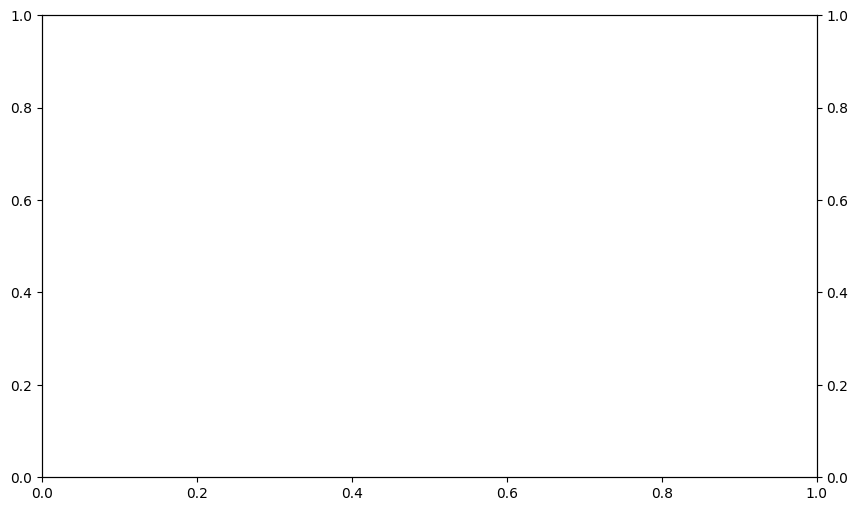

In [ ]:
# Simulation data
target_halo_id = 4

# Plotting/saving
#savefilename = 'Snap' + str(zoom_ID) + '_Halo_contamination.png' # .png name to save plot under
savefilename = '/home/b/babul/stlock/entropy_profiles/outputs/BAL_runs_energies.png'
thetitle = "Halo 3224 Simba-C L0 Energy - Varied level of accreted by BH's" # filepath/title of graph


# LOWEST -> HIGHEST BlackHoleFeedbackFactor

# (with 5 and 6) order = [20, 19, 18, 17, 26, 16, 25, 15, 24, 14, 23, 13, 22, 12, 21, 1, 27, 2, 28, 3, 29, 4, 30, 5, 31, 6, 32, 7, 8, 9, 10, 11]
order = [0, 1]
num_runs = 10


# -------------------------------------------------------------------------------------------------------------------------------------- SIM_DATA
import yt
import unyt
from unyt import unyt_quantity, unyt_array, km, s, Mpc, kg, m, Msun, kpc
from unyt import Gyr, Mpc, km, s
from unyt.physical_constants import G as G_unyt, kboltz, mp as mp_unyt  # G, k_B, m_p

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import caesar
import pynbody as pnb
import pynbody.units as u
import pynbody.array as pna
import seaborn as sns

import dill
import os
from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units, G
#from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units,

code = 'simba-c'

## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                    'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
        'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')

cmap = cm.plasma  # or plasma, magma, etc.
#norm = mcolors.Normalize(vmin=low_mass_range, vmax=high_mass_range)
#sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

cmap_total = plt.cm.get_cmap('coolwarm', 9)
# ------------------------------------------------------------------------------------------------------------------ Loop for each snap/caesar file!!!
color_n = 7
color_index = 1
# cmap = plt.cm.get_cmap('magma', 9)


fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

for run in range(num_runs):
    if run+1!=6:
        target_halo_id = 4
        if run+1==6:
            target_halo_id=5
        
        

        snap_file = f'/scratch/b/babul/stlock/snapshots/HyenasC/L0/halo_3224_finished_runs/BAL_variations/run{run+1:02}/snapshot_151.hdf5'
        caesarfilepath = f'/scratch/b/babul/stlock/snapshots/HyenasC/L0/halo_3224_finished_runs/BAL_variations/run{run+1:02}/caesarfile_snap151_test.hdf5'

        # ADD CAESAR FILEPATH HERE TO 

        snap = yt.load(snap_file)#, unit_system='cgs')
        data = snap.all_data()
        s = pnb.load(snap_file)

        # Get data, and some functions

        def gas_entropy(field, data):
            return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)

        def gas_entropy2(field, data):
            return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)

        snap.add_field(
            ("gas", "gas_entropy"),
            units="keV*cm**2",
            function=gas_entropy,
            sampling_type="cell",
        )

        snap.add_field(
            ("PartType0", "gas_entropy"),
            units="keV*cm**2",
            function=gas_entropy2,
            sampling_type="particle",
            force_override=True
        )



        gas_entropy = data['gas', 'entropy']

        obj = caesar.load(caesarfilepath)
        halo_data = obj.halos

        halo_center = halo_data[target_halo_id].minpotpos
        halo_center = halo_center.in_units('Mpc')
        print(halo_center)


        igrm = data.include_above(('PartType0', 'temperature'), 5e5, units='K')
        igrm = igrm.include_below(('PartType0', 'H_nuclei_density'), 0.13, units='cm**-3')
        igrm = igrm.include_equal(('PartType0', 'DelayTime'), 0)


        # Radial Binning

        # radial_bins = unyt.unyt_array(np.append([0], np.logspace(-3, np.log10(5), 30)), 'Mpc')
        radial_bins = unyt.unyt_array(np.append([0], np.logspace(-4, np.log10(5), 45)), 'Mpc')

        halo_center.in_units('Mpc')

        igrm_pos_x = igrm['gas', 'particle_position_x']
        igrm_pos_y = igrm['gas', 'particle_position_y']
        igrm_pos_z = igrm['gas', 'particle_position_z']

        # isolate igrm

        igrm_halo_center = ((igrm_pos_x-halo_center[0])**2 + (igrm_pos_y-halo_center[1])**2 + (igrm_pos_z-halo_center[2])**2)**0.5

        igrm_zoom_entropies = igrm['gas', 'entropy']
        igrm_zoom_masses = igrm['gas', 'mass']


        entropy_profile_median = []
        entropy_profile_mean = []
        entropy_profile_mass_weighted = []

        internal_energy_profile = []
        kinetic_energy_profile = []
        total_energy_profile = []
        for bin_lo, bin_hi in zip(radial_bins[:-1], radial_bins[1:]):
            radial_filter = np.logical_and(igrm_halo_center.in_units('Mpc').value>=bin_lo.in_units('Mpc').value,
                                        igrm_halo_center.in_units('Mpc').value<=bin_hi.in_units('Mpc').value)
            
            entropies = igrm_zoom_entropies[radial_filter]
            masses = igrm_zoom_masses[radial_filter]
            temperatures = igrm['gas', 'temperature'][radial_filter]
            velocities_x = igrm['gas', 'velocity_x'][radial_filter]
            velocities_y = igrm['gas', 'velocity_y'][radial_filter]
            velocities_z = igrm['gas', 'velocity_z'][radial_filter]


            # Calculate internal energy (1.5*nkT)
            v_squared = (velocities_x**2 + velocities_y**2 + velocities_z**2)
            kinetic_energy = 0.5 * masses * v_squared
            # Calculate kinetic energy (0.5*mv²)
            kinetic_energy = 0.5 * masses * v_squared
            
            # Calculate mass-weighted averages
            if sum(masses) > 0:
                avg_internal = np.average(internal_energy, weights=masses)
                avg_kinetic = np.average(kinetic_energy, weights=masses)
            else:
                avg_internal = np.nan
                avg_kinetic = np.nan
            
            internal_energy_profile.append(avg_internal)
            kinetic_energy_profile.append(avg_kinetic)
            total_energy_profile.append(avg_internal + avg_kinetic)

        from unyt import Msun, kpc, cm, keV, unyt_quantity
        from unyt.physical_constants import mp, kboltz, G  # ✅ use unyt's version


        # Constants
        mu = 0.59        # Mean molecular weight
        mu_e = 1.14      # Mean molecular weight per free electron

        # Load CAESAR catalog
        h = obj.simulation.hubble_constant
        omega_b = obj.simulation.omega_baryon
        omega_m = obj.simulation.omega_matter

        # Update f_b if desired
        f_b = omega_b / omega_m

        # Critical density
        H0_si = (100 * h * 1e3) / (3.086e22)  # H0 in 1/s
        rho_crit_si = 3 * H0_si**2 / (8 * np.pi * 6.6743e-11)  # kg/m^3
        rho_crit = unyt_quantity(rho_crit_si, "kg/m**3").to("Msun/kpc**3")

        # Choose your halo
        halo = obj.halos[target_halo_id]  # Replace with desired index or search method

        M500 = unyt_quantity(halo.virial_quantities['m500c'].in_units("Msun"), "Msun")
        T500 = (G * M500 * mu * mp / R500).to("keV") # removing 1/kb here
        R500 = halo_data[target_halo_id].virial_quantities['r500c'].in_units('Mpc')
        
        
        radial_bin_centres = (radial_bins[:-1] + radial_bins[1:])/2.
        radial_bin_centres_logged = np.log10(radial_bin_centres)
        log_radial_bin_centres = (np.log10(radial_bins[:-1]) + np.log10(radial_bins[1:]))/2.
        log_radial_bin_centres_unlogged = 10**log_radial_bin_centres

        normalized_r = radial_bin_centres/R500.value
        normalized_k_mean = np.array(entropy_profile_mean)/K500.value
        normalized_k_median = np.array(entropy_profile_median)/K500.value

        U500 = 1.5 * kboltz * T500  # T500 is already calculated in your code

        # Normalize the energy profiles
        normalized_u_int = np.array(internal_energy_profile)/U500.value
        normalized_u_tot = np.array(total_energy_profile)/U500.value

        # Convert to log scale for plotting
        log_u_int = np.log10(normalized_u_int)
        log_u_tot = np.log10(normalized_u_tot)
        log_r = np.log10(normalized_r)
        # Then modify your plotting section to include these new profiles:
        """
            plt.plot(
            log_r,
            log_k,
            color=cmap_sim(run),
            lw=1,
            ls='-',
            zorder=60,
            label=f'simulation {run+1} (Entropy)'
        )
        """

        ax1.plot(
            log_r,
            log_u_int,
            color=cmap_sim(run),
            lw=2,
            ls='--',
            zorder=60,
            label=f'Run {run+1} Internal'
        )
        
        ax2.plot(
            log_r,
            log_u_tot,
            color=cmap_sim(run),
            lw=2,
            ls='--',
            zorder=60,
            label=f'Run {run+1} Total'
        )
        
        color_index+=1
color_index = 1
# ------------------------------------------------------------------------------------------------------------------ end Loop!!!


print("Velocity units pre-conversion:", vx.units)  # Should be km/s
print("Velocity squared units:", v_sq.units)      # Should be cm²/s²
print("Kinetic energy units:", kinetic_energy.units)  # Should be keV


#====================================================================================================================================================

